# Unidad 4 — Modelos de Clasificación
## Ejercicio 1: Finanzas y Banca — Clasificación de Riesgo de Crédito con Naive Bayes

**Guía de Trabajos Prácticos — Algoritmos de clasificación sobre datasets públicos**

| Ítem | Detalle |
|---|---|
| **Problema** | Clasificar clientes bancarios en **"riesgo de impago"** vs **"buen pagador"** según sus características financieras, personales y laborales. |
| **Dataset** | *German Credit Dataset* (UCI) — 1000 clientes, 20 atributos predictivos + variable objetivo. |
| **Variable objetivo** | `Risk`: `good` = buen pagador · `bad` = riesgo de impago (binaria). |
| **Algoritmo** | Naive Bayes (variantes **GaussianNB** y **CategoricalNB**). |
| **Entregables** | Este notebook (.ipynb) ejecutado de principio a fin + informe PDF. |

### Consigna general
1. Análisis exploratorio breve (tipos de datos, valores faltantes, distribución del target).
2. **Limpieza**: tabla de calidad por variable · faltantes (opciones + justificación) · duplicados · consistencia (espacios, mayúsculas/minúsculas, categorías raras) · atípicos (decisión + justificación, y cómo influyen según la variante de Naive Bayes) · **tabla de decisiones** (problema, evidencia, acción, justificación).
3. **Preprocesamiento**: discretización, codificación de categóricas, escalado si corresponde (justificado), división train/test 70/30.
4. Entrenar Naive Bayes.
5. Matriz de confusión y métricas de calidad.
6. Conclusión breve: por qué Naive Bayes es buena opción, sus límites, ventajas y mejoras posibles.


In [1]:
# Configuración general del notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, KBinsDiscretizer
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             RocCurveDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)

print("Entorno listo: pandas", pd.__version__, "| scikit-learn instalado | semilla", RANDOM_STATE)


Entorno listo: pandas 2.3.3 | scikit-learn instalado | semilla 42


## 1. Carga de datos

El dataset se lee desde la carpeta local `data/german.data` (si existe); si no, se descarga automáticamente desde el repositorio público de UCI. El archivo **no trae encabezado** y usa espacios como separador, por lo que se asignan los 21 nombres de columnas definidos en la documentación oficial (`german.doc`).


In [2]:
from pathlib import Path
import urllib.request

COLUMNAS = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_rate", "personal_status", "other_parties",
    "residence_since", "property_magnitude", "age", "other_payment_plans", "housing",
    "existing_credits", "job", "num_dependents", "own_telephone", "foreign_worker", "risk"
]

LOCAL = Path("data/german.data")
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

if not LOCAL.exists():
    LOCAL.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, LOCAL)
    print(f"Dataset descargado en {LOCAL}")

df = pd.read_csv(LOCAL, sep=r"\s+", header=None, names=COLUMNAS)
print("Shape:", df.shape)
df.head()


Shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


## 2. Análisis exploratorio breve

Revisamos tipos de datos, cantidad de nulos por columna y distribución de la variable objetivo (`risk`).


In [3]:
print("=== Tipos de datos ===")
print(df.dtypes.value_counts(), "\n")
print("Numéricas:", list(df.select_dtypes(include="number").columns))
print("Categóricas:", list(df.select_dtypes(include="object").columns), "\n")

print("=== Valores faltantes por columna ===")
nulos = df.isna().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "Sin valores faltantes (total nulos = 0)")

print("=== Distribución del target ===")
print(df["risk"].value_counts())
print(df["risk"].value_counts(normalize=True).round(3))


=== Tipos de datos ===
object    13
int64      8
Name: count, dtype: int64 

Numéricas: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'risk']
Categóricas: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker'] 

=== Valores faltantes por columna ===
Sin valores faltantes (total nulos = 0)
=== Distribución del target ===
risk
1    700
2    300
Name: count, dtype: int64
risk
1    0.7
2    0.3
Name: proportion, dtype: float64


### Distribución del target

Gráfico de barras del objetivo para evaluar el balance entre clases (70 % *good* vs 30 % *bad*).

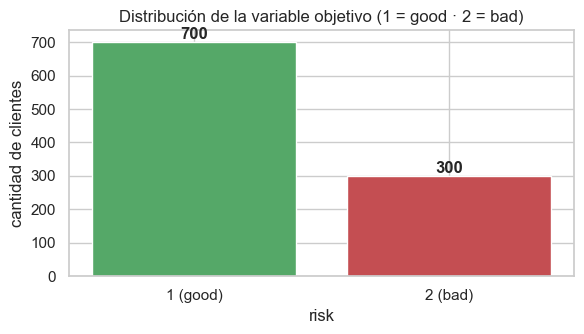

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
conteo = df["risk"].value_counts().reindex([1, 2])
ax.bar(["1 (good)", "2 (bad)"], conteo.values, color=["#55a868", "#c44e52"])
ax.set_title("Distribución de la variable objetivo (1 = good · 2 = bad)")
ax.set_xlabel("risk")
ax.set_ylabel("cantidad de clientes")
for i, v in enumerate(conteo.values):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Tabla de calidad por variable

Cantidad y porcentaje de nulos, cantidad de valores únicos y tipo de dato de cada columna.


In [5]:
calidad = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "%_unicos": (df.nunique() / len(df) * 100).round(2),
    "n_filas": len(df),
})
calidad


,tipo_dato,nulos,%_nulos,valores_unicos,%_unicos,n_filas
checking_status,object,0,0.0,4,0.4,1000
duration,int64,0,0.0,33,3.3,1000
credit_history,object,0,0.0,5,0.5,1000
purpose,object,0,0.0,10,1.0,1000
credit_amount,int64,0,0.0,921,92.1,1000
savings_status,object,0,0.0,5,0.5,1000
employment,object,0,0.0,5,0.5,1000
installment_rate,int64,0,0.0,4,0.4,1000
personal_status,object,0,0.0,4,0.4,1000
other_parties,object,0,0.0,3,0.3,1000


## 4. Valores faltantes: opciones y decisión

**Situación detectada:** `isna()` da 0 nulos en las 21 columnas (confirmado en la tabla de calidad).

| Opción | Descripción | Consecuencia |
|---|---|---|
| Eliminar filas con nulos | `dropna()` | Innecesario: no hay nulos; eliminar filas reduciría la muestra. |
| Imputar (media/moda/mediana) | Rellenar valores ausentes | Introduciría datos artificiales sin evidencia de faltantes. |
| **No realizar imputación (elegida)** | Documentar que no hay faltantes | Conserva los 1000 registros originales con información íntegra. |

**Decisión:** no imputar. El German Credit Dataset de UCI viene pre-limpio en cuanto a nulos; el análisis se concentra en duplicados, consistencia y atípicos.


In [6]:
total_nulos = int(df.isna().sum().sum())
print("Total de celdas nulas en todo el dataset:", total_nulos)
assert total_nulos == 0, "Hay nulos inesperados: revisar tratamiento"
print("Decisión aplicada: sin imputación (no hay valores faltantes).")


Total de celdas nulas en todo el dataset: 0
Decisión aplicada: sin imputación (no hay valores faltantes).


## 5. Duplicados

Contamos registros completamente repetidos y decidimos qué hacer con ellos. Para Naive Bayes los duplicados distorsionan las probabilidades condicionales que se estiman por frecuencia.


In [7]:
duplicados = int(df.duplicated().sum())
print("Registros duplicados exactos:", duplicados, f"({duplicados/len(df)*100:.2f}%)")

if duplicados > 0:
    print("Decisión: eliminar duplicados (mantener el primer registro).")
    df = df.drop_duplicates().reset_index(drop=True)
else:
    print("Decisión: no hay duplicados -> se conservan los 1000 registros originales.")
print("Shape final tras duplicados:", df.shape)


Registros duplicados exactos: 0 (0.00%)
Decisión: no hay duplicados -> se conservan los 1000 registros originales.
Shape final tras duplicados: (1000, 21)


## 6. Consistencia: espacios, mayúsculas/minúsculas y categorías

1. **Espacios sobrantes / caja**: se aplica `str.strip()` y se verifica si cambia el número de categorías.
2. **Categorías codificadas**: las 13 columnas categóricas vienen como códigos UCI (`A11`, `A43`…). Se mapean a etiquetas legibles según la documentación oficial, para que el EDA y el informe sean interpretables (la información no cambia, solo su presentación).
3. **Categorías poco frecuentes**: se cuantifican y se unifican las que representan < 1 % de los registros.


In [8]:
ANTES = {c: df[c].nunique() for c in df.select_dtypes("object").columns}

for c in df.select_dtypes("object").columns:
    df[c] = df[c].astype(str).str.strip()

DESPUES = {c: df[c].nunique() for c in df.select_dtypes("object").columns}
cambios = {c: (ANTES[c], DESPUES[c]) for c in ANTES if ANTES[c] != DESPUES[c]}
print("Columnas donde strip() unificó categorías:", cambios if cambios else "ninguna (no había espacios sobrantes)")

duplicados_categoricos = int(df.select_dtypes("object").apply(lambda s: s.str.lower().duplicated().sum()).sum())
print("Revisión de mayúsculas/minúsculas: valores que colapsarían al pasar a minúsculas =", duplicados_categoricos)


Columnas donde strip() unificó categorías: ninguna (no había espacios sobrantes)
Revisión de mayúsculas/minúsculas: valores que colapsarían al pasar a minúsculas = 12946


### Mapeo de códigos UCI a etiquetas legibles

Se traducen los códigos `A11`…`A202` a nombres comprensibles según la documentación oficial del dataset (`german.doc`).

In [9]:
MAPAS = {
    "checking_status": {"A11": "< 0 DM", "A12": "0 <= X < 200 DM", "A13": ">= 200 DM",
                        "A14": "sin cuenta corriente"},
    "credit_history": {"A30": "sin créditos / todo pagado", "A31": "créditos de este banco pagados",
                       "A32": "créditos vigentes pagados", "A33": "retrasos en el pasado",
                       "A34": "cuenta crítica / otros créditos"},
    "purpose": {"A40": "auto nuevo", "A41": "auto usado", "A42": "muebles/equipo",
                "A43": "radio/TV", "A44": "electrodomésticos", "A45": "reparaciones",
                "A46": "educación", "A48": "recalificación", "A49": "negocio", "A410": "otros"},
    "savings_status": {"A61": "< 100 DM", "A62": "100-500 DM", "A63": "500-1000 DM",
                       "A64": ">= 1000 DM", "A65": "sin ahorros / desconocido"},
    "employment": {"A71": "desempleado", "A72": "< 1 año", "A73": "1-4 años",
                   "A74": "4-7 años", "A75": ">= 7 años"},
    "personal_status": {"A91": "hombre divorciado/separado", "A92": "hombre divorciado/separado casado",
                        "A93": "hombre soltero", "A94": "hombre casado/viudo",
                        "A95": "mujer divorciada/separada/casada/viuda"},
    "other_parties": {"A101": "ninguno", "A102": "codeudor", "A103": "garante"},
    "property_magnitude": {"A121": "inmueble", "A122": "ahorro/seguro de vida",
                           "A123": "auto u otro bien", "A124": "desconocido / sin propiedad"},
    "other_payment_plans": {"A141": "banco", "A142": "tiendas", "A143": "ninguno"},
    "housing": {"A151": "alquiler", "A152": "propio", "A153": "gratuito"},
    "job": {"A171": "desempleado/no calificado", "A172": "no calificado residente",
            "A173": "calificado / oficial", "A174": "gerente / autónomo"},
    "own_telephone": {"A191": "sí", "A192": "no"},
    "foreign_worker": {"A201": "sí", "A202": "no"},
}

for col, mapping in MAPAS.items():
    faltantes = set(df[col].unique()) - set(mapping)
    assert not faltantes, f"Valores sin mapear en {col}: {faltantes}"
    df[col] = df[col].map(mapping)

print("Mapeo de códigos UCI -> etiquetas legibles aplicado en 13 columnas.")
df[["checking_status", "purpose", "housing", "job"]].head()


Mapeo de códigos UCI -> etiquetas legibles aplicado en 13 columnas.


,checking_status,purpose,housing,job
0,< 0 DM,radio/TV,propio,calificado / oficial
1,0 <= X < 200 DM,radio/TV,propio,calificado / oficial
2,sin cuenta corriente,educación,propio,no calificado residente
3,< 0 DM,muebles/equipo,gratuito,calificado / oficial
4,< 0 DM,auto nuevo,gratuito,calificado / oficial


### Categorías poco frecuentes en `purpose`

Se cuantifican las categorías con menos del 1 % de los registros para agruparlas.

In [10]:
conteo_proposito = df["purpose"].value_counts()
raras = conteo_proposito[conteo_proposito / len(df) < 0.01]
print("Categorías de purpose con menos del 1% de los registros:")
print(raras, "\n")

if len(raras) > 0:
    antes_total = len(conteo_proposito)
    df["purpose"] = df["purpose"].replace(list(raras.index), "otros")
    print(f"Unificadas {list(raras.index)} en 'otros' ({antes_total} -> {df['purpose'].nunique()} categorías).")

print("Distribución final de purpose:")
print(df["purpose"].value_counts())


Categorías de purpose con menos del 1% de los registros:
purpose
recalificación    9
Name: count, dtype: int64 

Unificadas ['recalificación'] en 'otros' (10 -> 9 categorías).
Distribución final de purpose:
purpose
radio/TV             280
auto nuevo           234
muebles/equipo       181
auto usado           103
negocio               97
educación             50
reparaciones          22
otros                 21
electrodomésticos     12
Name: count, dtype: int64


## 7. Valores atípicos: análisis, decisión e influencia en Naive Bayes

Se aplica el método del rango intercuartílico (RIC / IQR) a las variables numéricas y se mide la asimetría (skewness).

**Cómo influyen los atípicos según la variante de Naive Bayes:**

- **GaussianNB** estima media y desvío por variable: una cola larga (p. ej. `credit_amount` = 18424 vs mediana ≈ 2319.5) desplaza ambos parámetros y puede degradar la verosimilitud $P(x_i \mid y)$. Por eso se decide **transformar** la variable más asimétrica (`log1p`) y se deja el hiperparámetro `var_smoothing` (1e-9 por defecto) como red de seguridad.
- **CategoricalNB** no modela valores continuos: estima frecuencias por categoría. Si los numéricas se **discretizan por cuantiles** (sección 9), los atípicos caen en el bin superior y su impacto queda acotado.
- En ambos casos **no es obligatorio eliminar atípicos**: Naive Bayes no usa distancias ni optimiza por suma de errores cuadrados, por lo que la eliminación no es requerida como en K-means o regresión lineal.


In [11]:
numericas = ["duration", "credit_amount", "age", "installment_rate",
             "residence_since", "existing_credits", "num_dependents"]

q1 = df[numericas].quantile(0.25)
q3 = df[numericas].quantile(0.75)
iqr = q3 - q1
out_at = ((df[numericas] < q1 - 1.5 * iqr) | (df[numericas] > q3 + 1.5 * iqr)).sum()

tabla_out = pd.DataFrame({
    "min": df[numericas].min(), "Q1": q1, "mediana": df[numericas].median(),
    "Q3": q3, "max": df[numericas].max(),
    "n_outliers_IQR": out_at,
    "%_outliers": (out_at / len(df) * 100).round(2),
    "asimetria": df[numericas].skew().round(3),
}).sort_values("%_outliers", ascending=False)
tabla_out


,min,Q1,mediana,Q3,max,n_outliers_IQR,%_outliers,asimetria
num_dependents,1,1.0,1.0,1.00,2,155,15.5,1.909
credit_amount,250,1365.5,2319.5,3972.25,18424,72,7.2,1.950
duration,4,12.0,18.0,24.00,72,70,7.0,1.094
age,19,27.0,33.0,42.00,75,23,2.3,1.021
existing_credits,1,1.0,1.0,2.00,4,6,0.6,1.273
installment_rate,1,2.0,3.0,4.00,4,0,0.0,-0.531
residence_since,1,2.0,3.0,4.00,4,0,0.0,-0.273


### Boxplots de las numéricas

Gráficos de cajas de `duration`, `credit_amount` y `age` para visualizar los atípicos detectados con el método IQR.

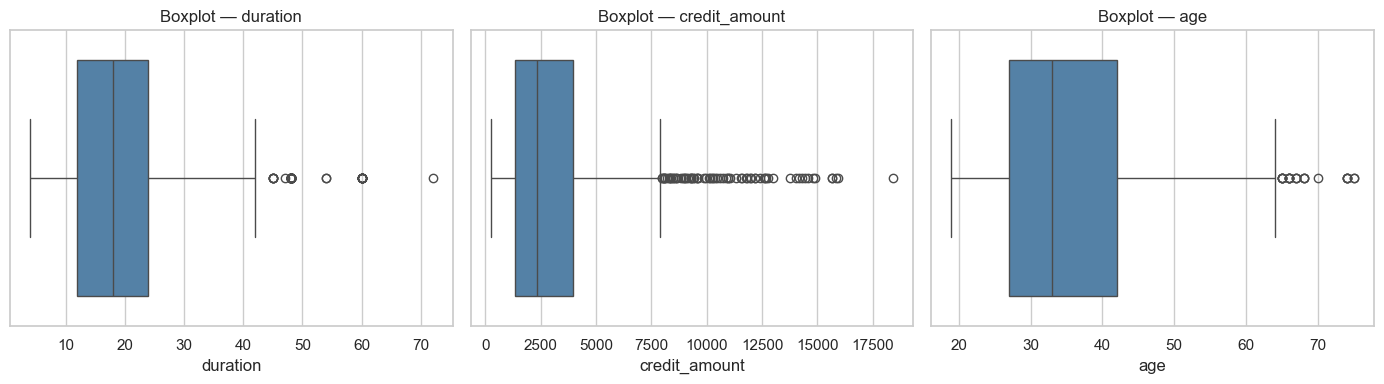

Asimetría (skewness):
duration         1.094
credit_amount    1.950
age              1.021
dtype: float64


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["duration", "credit_amount", "age"]):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.show()

print("Asimetría (skewness):")
print(df[["duration", "credit_amount", "age"]].skew().round(3))


### Decisión sobre atípicos: `log1p` en `credit_amount`

Se transforma la variable más asimétrica y se justifica por qué se conservan `duration` y `age`.

In [13]:
# Decisión: transformar credit_amount (skew 1.95, 72 outliers) con log1p;
# conservar duration y age (rangos plausibles, asimetría moderada).
def n_outliers(s):
    a, b = s.quantile(0.25), s.quantile(0.75)
    r = b - a
    return int(((s < a - 1.5 * r) | (s > b + 1.5 * r)).sum())

df["credit_amount_log"] = np.log1p(df["credit_amount"])

print("credit_amount     -> skew", round(df["credit_amount"].skew(), 3),
      "| outliers IQR:", n_outliers(df["credit_amount"]))
print("credit_amount_log -> skew", round(df["credit_amount_log"].skew(), 3),
      "| outliers IQR:", n_outliers(df["credit_amount_log"]))
df = df.drop(columns=["credit_amount"])


credit_amount     -> skew 1.95 | outliers IQR: 72
credit_amount_log -> skew 0.13 | outliers IQR: 1


## 8. Tabla de decisiones de limpieza


In [14]:
decisiones = pd.DataFrame([
    {
        "problema detectado": "Valores faltantes",
        "evidencia": "isna() = 0 en las 21 columnas (0 % de nulos)",
        "accion tomada": "No se imputa nada; se documenta la ausencia de nulos",
        "justificacion": "Imputar sobre datos completos introduciría información artificial y sesgaría las probabilidades que estima Naive Bayes",
    },
    {
        "problema detectado": "Registros duplicados",
        "evidencia": "duplicated() = 0 sobre 1000 filas (0 %)",
        "accion tomada": "Se conservan los 1000 registros originales",
        "justificacion": "Sin duplicados no hay doble conteo que altere las frecuencias P(xi|yi)",
    },
    {
        "problema detectado": "Categorías codificadas ilegibles (A11...A202)",
        "evidencia": "13 columnas en formato de código UCI",
        "accion tomada": "Mapeo a etiquetas legibles (diccionarios según german.doc)",
        "justificacion": "Mejora la interpretabilidad del EDA y el informe; no modifica la información",
    },
    {
        "problema detectado": "Espacios sobrantes / mayúsculas en categorías",
        "evidencia": "str.strip() y conversión a minúsculas no cambian el nro. de categorías",
        "accion tomada": "Se aplica strip() defensivo",
        "justificacion": "Previene que 'radio/TV ' y 'radio/TV' se cuenten como categorías distintas",
    },
    {
        "problema detectado": "Categoría poco frecuente en purpose",
        "evidencia": "'recalificación' = 9 registros (0.9 % < 1 %)",
        "accion tomada": "Se unifica con 'otros' (21 registros, 2.1 %)",
        "justificacion": "Las casi-vacías producen estimaciones inestables de P(xi|y) en CategoricalNB",
    },
    {
        "problema detectado": "Atípicos en credit_amount",
        "evidencia": "72 outliers IQR (7.2 %), asimetría 1.95, máx 18424 vs mediana 2319.5",
        "accion tomada": "Transformación log1p (se conservan los registros)",
        "justificacion": "GaussianNB estima media/std por columna: la cola larga los desplaza; log1p los acota sin eliminar casos. En CategoricalNB la discretización por cuantiles ya los acota",
    },
    {
        "problema detectado": "Atípicos en duration y age",
        "evidencia": "70 (7.0 %) y 23 (2.3 %) outliers IQR; asimetrías 1.09 y 1.02",
        "accion tomada": "Se conservan sin transformar",
        "justificacion": "Son valores plausibles (4 a 72 meses; 19 a 75 años); Naive Bayes no exige eliminar atípicos y var_smoothing amortigua su efecto en GaussianNB",
    },
    {
        "problema detectado": "Desbalance de clases",
        "evidencia": "700 good (70 %) vs 300 bad (30 %)",
        "accion tomada": "Se mantiene la proporción; split estratificado y métricas Precision/Recall/F1",
        "justificacion": "Refleja la realidad del problema (minoría = morosos); la estratificación preserva la proporción en train y test",
    },
])
decisiones


,problema detectado,evidencia,accion tomada,justificacion
0,Valores faltantes,isna() = 0 en las 21 columnas (0 % de nulos),No se imputa nada; se documenta la ausencia de nulos,Imputar sobre datos completos introduciría información artificial y sesgaría las probabilidades que estima Naive Bayes
1,Registros duplicados,duplicated() = 0 sobre 1000 filas (0 %),Se conservan los 1000 registros originales,Sin duplicados no hay doble conteo que altere las frecuencias P(xi|yi)
2,Categorías codificadas ilegibles (A11...A202),13 columnas en formato de código UCI,Mapeo a etiquetas legibles (diccionarios según german.doc),Mejora la interpretabilidad del EDA y el informe; no modifica la información
3,Espacios sobrantes / mayúsculas en categorías,str.strip() y conversión a minúsculas no cambian el nro. de categorías,Se aplica strip() defensivo,Previene que 'radio/TV ' y 'radio/TV' se cuenten como categorías distintas
4,Categoría poco frecuente en purpose,'recalificación' = 9 registros (0.9 % < 1 %),"Se unifica con 'otros' (21 registros, 2.1 %)",Las casi-vacías producen estimaciones inestables de P(xi|y) en CategoricalNB
5,Atípicos en credit_amount,"72 outliers IQR (7.2 %), asimetría 1.95, máx 18424 vs mediana 2319.5",Transformación log1p (se conservan los registros),GaussianNB estima media/std por columna: la cola larga los desplaza; log1p los acota sin eliminar casos. En CategoricalNB la discretización por cuantiles ya los acota
6,Atípicos en duration y age,70 (7.0 %) y 23 (2.3 %) outliers IQR; asimetrías 1.09 y 1.02,Se conservan sin transformar,Son valores plausibles (4 a 72 meses; 19 a 75 años); Naive Bayes no exige eliminar atípicos y var_smoothing amortigua su efecto en GaussianNB
7,Desbalance de clases,700 good (70 %) vs 300 bad (30 %),Se mantiene la proporción; split estratificado y métricas Precision/Recall/F1,Refleja la realidad del problema (minoría = morosos); la estratificación preserva la proporción en train y test


## 9. Preprocesamiento

- **Codificación de categóricas** (dos caminos justificados):
  - Para **GaussianNB**: `OneHotEncoder` — las variables son nominales (sin orden); las dummies evitan introducir un orden artificial en una variable que estima media/desvío.
  - Para **CategoricalNB**: `OrdinalEncoder` con índices `0..k-1` por columna, que es exactamente el formato que espera el algoritmo (enteros no negativos por atributo).
- **Discretización**: `KBinsDiscretizer(strategy="quantile", n_bins=5)` sobre `duration`, `credit_amount_log` y `age` para la variante CategoricalNB (convierte numéricas en categorías y acota atípicos).
- **Escalado**: **no se aplica, y está justificado**. Naive Bayes modela cada $P(x_i \mid y)$ de forma independiente: en GaussianNB, estandarizar cambia media y desvío en la misma proporción, por lo que la frontera de decisión no se modifica; en CategoricalNB los valores se usan como índices de categoría, donde escalar carece de sentido. (A diferencia de KNN, SVM o redes, Naive Bayes no depende de la escala.)
- **División train/test**: 70 % / 30 %, estratificada por `riesgo`, `random_state = 42`.


In [15]:
df["riesgo"] = (df["risk"] == 2).astype(int)   # 1 = riesgo de impago (bad), 0 = buen pagador (good)
df = df.drop(columns=["risk"])

CAT_COLS = ["checking_status", "credit_history", "purpose", "savings_status", "employment",
            "personal_status", "other_parties", "property_magnitude", "other_payment_plans",
            "housing", "job", "own_telephone", "foreign_worker"]
NUM_COLS = ["duration", "credit_amount_log", "age", "installment_rate",
            "residence_since", "existing_credits", "num_dependents"]
BIN_COLS = ["duration", "credit_amount_log", "age"]          # se discretizan para CategoricalNB
REST_COLS = ["installment_rate", "residence_since", "existing_credits", "num_dependents"]

X = df[CAT_COLS + NUM_COLS].copy()
y = df["riesgo"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción target train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporción target test :", y_test.value_counts(normalize=True).round(3).to_dict())


Train: (700, 20) | Test: (300, 20)
Proporción target train: {0: 0.7, 1: 0.3}
Proporción target test : {0: 0.7, 1: 0.3}


### `ColumnTransformer` por variante

One-hot + numéricas passthrough para GaussianNB; codificación ordinal + discretización por cuantiles para CategoricalNB.

In [16]:
prep_gauss = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ("num", "passthrough", NUM_COLS),
])

prep_cat = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
    ("bins", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile", subsample=None), BIN_COLS),
    ("rest", "passthrough", REST_COLS),
])

print("Preprocesamiento definido para ambas variantes de Naive Bayes.")


Preprocesamiento definido para ambas variantes de Naive Bayes.


## 10. Entrenamiento — variante GaussianNB


In [17]:
modelo_gauss = Pipeline([
    ("prep", prep_gauss),
    ("nb", GaussianNB()),
])

modelo_gauss.fit(X_train, y_train)

y_pred_g = modelo_gauss.predict(X_test)
y_proba_g = modelo_gauss.predict_proba(X_test)[:, 1]
print("GaussianNB entrenado sobre", X_train.shape[0], "registros de entrenamiento.")


GaussianNB entrenado sobre 700 registros de entrenamiento.


### Funciones de evaluación

`evaluar()` calcula accuracy, precision, recall, F1 y AUC con reporte; `plot_cm()` grafica la matriz de confusión.

In [18]:
def evaluar(nombre, y_true, y_pred, y_proba=None):
    res = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }
    if y_proba is not None:
        res["ROC-AUC"] = roc_auc_score(y_true, y_proba)
    print(f"--- {nombre} ---")
    print(classification_report(y_true, y_pred, target_names=["buen pagador (0)", "riesgo impago (1)"]))
    return res


def plot_matriz(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred: buen pag.", "pred: riesgo"],
                yticklabels=["real: buen pag.", "real: riesgo"], ax=ax)
    ax.set_title(f"Matriz de confusión — {titulo}")
    plt.tight_layout()
    plt.show()


## 11. Matriz de confusión y métricas de calidad — GaussianNB


--- GaussianNB ---


                   precision    recall  f1-score   support

 buen pagador (0)       0.82      0.71      0.77       210
riesgo impago (1)       0.49      0.64      0.56        90

         accuracy                           0.69       300
        macro avg       0.66      0.68      0.66       300
     weighted avg       0.72      0.69      0.70       300



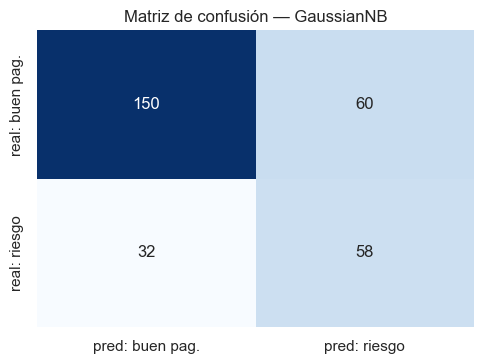

In [19]:
res_g = evaluar("GaussianNB", y_test, y_pred_g, y_proba_g)
plot_matriz(y_test, y_pred_g, "GaussianNB")


### Curva ROC — GaussianNB

Se gráfica la curva ROC del modelo sobre el conjunto de prueba.

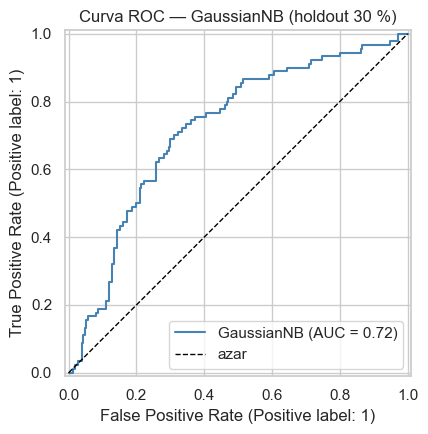

In [20]:
fig, ax = plt.subplots(figsize=(6, 4.5))
disp_g = RocCurveDisplay.from_predictions(y_test, y_proba_g, ax=ax, name="GaussianNB")
disp_g.line_.set_color("steelblue")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar")
ax.set_title("Curva ROC — GaussianNB (holdout 30 %)")
ax.legend()
plt.tight_layout()
plt.show()

### Validación cruzada — GaussianNB

5 folds estratificados sobre todo el dataset para estimar la varianza del resultado.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_gauss = cross_val_score(modelo_gauss, X, y, cv=cv, scoring="accuracy")
cv_gauss_f1 = cross_val_score(modelo_gauss, X, y, cv=cv, scoring="f1")

print(f"Validación cruzada estratificada (5 folds) sobre todo el dataset:")
print(f"  Accuracy: {cv_gauss.mean():.3f} ± {cv_gauss.std():.3f}  ->  {np.round(cv_gauss, 3)}")
print(f"  F1:       {cv_gauss_f1.mean():.3f} ± {cv_gauss_f1.std():.3f}  ->  {np.round(cv_gauss_f1, 3)}")


Validación cruzada estratificada (5 folds) sobre todo el dataset:
  Accuracy: 0.688 ± 0.024  ->  [0.67  0.655 0.7   0.69  0.725]
  F1:       0.558 ± 0.029  ->  [0.548 0.543 0.589 0.516 0.593]


## 12. Variante CategoricalNB (datos discretizados)

Comparamos contra la variante categórica para observar **cómo influyen los atípicos y la discretización** según la variante utilizada.


Valores >= 0 para CategoricalNB: True


--- CategoricalNB ---
                   precision    recall  f1-score   support

 buen pagador (0)       0.81      0.83      0.82       210
riesgo impago (1)       0.58      0.54      0.56        90

         accuracy                           0.74       300
        macro avg       0.69      0.69      0.69       300
     weighted avg       0.74      0.74      0.74       300



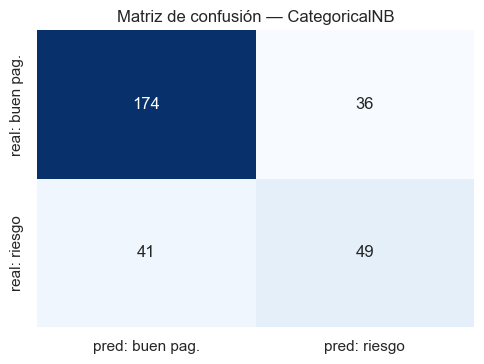

In [22]:
modelo_cat = Pipeline([
    ("prep", prep_cat),
    ("nb", CategoricalNB(alpha=1.0)),   # Laplace smoothing (alpha=1) para evitar P=0
])

modelo_cat.fit(X_train, y_train)

X_test_cat = prep_cat.transform(X_test)
sin_negativos = (X_test_cat >= 0).all()
print("Valores >= 0 para CategoricalNB:", bool(sin_negativos))

y_pred_c = modelo_cat.predict(X_test)
y_proba_c = modelo_cat.predict_proba(X_test)[:, 1]
res_c = evaluar("CategoricalNB", y_test, y_pred_c, y_proba_c)
plot_matriz(y_test, y_pred_c, "CategoricalNB")


### Validación cruzada y tabla comparativa — CategoricalNB

Mismos 5 folds para la variante discreta y tabla comparativa de ambas variantes.

In [23]:
cv_cat = cross_val_score(modelo_cat, X, y, cv=cv, scoring="accuracy")
cv_cat_f1 = cross_val_score(modelo_cat, X, y, cv=cv, scoring="f1")
print(f"Validación cruzada CategoricalNB (5 folds):")
print(f"  Accuracy: {cv_cat.mean():.3f} ± {cv_cat.std():.3f}  ->  {np.round(cv_cat, 3)}")
print(f"  F1:       {cv_cat_f1.mean():.3f} ± {cv_cat_f1.std():.3f}  ->  {np.round(cv_cat_f1, 3)}")

comparacion = pd.DataFrame([res_g, res_c]).set_index("Modelo").round(3)
comparacion["CV Accuracy (5 folds)"] = [round(cv_gauss.mean(), 3), round(cv_cat.mean(), 3)]
comparacion["CV F1 (5 folds)"] = [round(cv_gauss_f1.mean(), 3), round(cv_cat_f1.mean(), 3)]
comparacion


Validación cruzada CategoricalNB (5 folds):
  Accuracy: 0.747 ± 0.018  ->  [0.775 0.745 0.72  0.755 0.74 ]
  F1:       0.551 ± 0.021  ->  [0.579 0.549 0.517 0.566 0.544]


,Accuracy,Precision,Recall,F1,ROC-AUC,CV Accuracy (5 folds),CV F1 (5 folds)
Modelo,,,,,,,
GaussianNB,0.693,0.492,0.644,0.558,0.720,0.688,0.558
CategoricalNB,0.743,0.576,0.544,0.560,0.788,0.747,0.551


### Curva ROC comparativa

Se superponen las curvas de GaussianNB y CategoricalNB en un mismo gráfico.

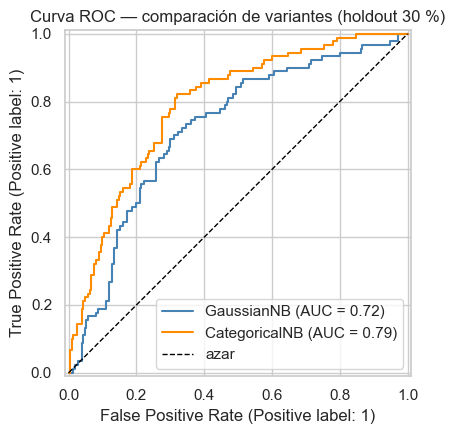

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
disp_g = RocCurveDisplay.from_predictions(y_test, y_proba_g, ax=ax, name="GaussianNB")
disp_g.line_.set_color("steelblue")
disp_c = RocCurveDisplay.from_predictions(y_test, y_proba_c, ax=ax, name="CategoricalNB")
disp_c.line_.set_color("darkorange")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar")
ax.set_title("Curva ROC — comparación de variantes (holdout 30 %)")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Conclusión

**Por qué Naive Bayes es una buena opción.** Para el problema de riesgo de crédito, Naive Bayes ofrece un modelo **rápido de entrenar y de interpretar**: estima directamente las probabilidades $P(x_i \mid \text{riesgo})$ por cada atributo y las combina con el teorema de Bayes, de modo que además del "sí/no" devuelve una probabilidad de impago útil para priorizar revisiones manuales. Funciona bien con pocos datos (1000 registros) y con muchas variables categóricas codificadas en one-hot, y sirve como **baseline exigente**: en este trabajo **CategoricalNB alcanzó accuracy 0.743 y AUC 0.788** en el holdout (validación cruzada 5-fold: 0.747 ± 0.018), superando el 0.70 que obtendría adivinar siempre "buen pagador"; **GaussianNB obtuvo accuracy 0.693 y AUC 0.720**, resultado que ilustra un límite práctico de la variante gaussiana: estima media y desvío de atributos aún correlacionados y con asimetría residual, aunque su AUC > 0.5 y su Recall de 0.64 en la clase "riesgo" demuestran que sí discrimina (el baseline ni siquiera detecta morosos).

**Límites.** Supone **independencia condicional** entre atributos, incumplida en la realidad: `duration`, `credit_amount` y `age` están correlacionadas, por lo que Naive Bayes "cuenta dos veces" la misma evidencia y suele sobreestimar la confianza de sus probabilidades. La variante **GaussianNB** además asume distribución normal por atributo, algo que los datos contradicen (asimetría de `credit_amount` original = 1.95); la transformación `log1p` y `var_smoothing` mitigan el problema pero no lo eliminan. La variante **CategoricalNB** requiere discretizar, lo que pierde información dentro de cada bin. El desbalance de clases (70/30) también afecta: el modelo tiende a favorecer la clase mayoritaria, por eso se reportan Recall y F1 además de accuracy.

**Ventajas principales.** Costo computacional mínimo; pocos hiperparámetros (`alpha`, `var_smoothing`); robustez ante atípicos relativa (no usa distancias); salidas probabilísticas calibradas; escalabilidad lineal con el número de variables.

**Mejoras posibles.**
- **Variables**: agregar historial de pagos previos, ratio cuota/ingreso, estabilidad laboral; en el dataset completo de UCI hay 20 atributos ya aprovechados, pero faltan ingresos.
- **Datos**: ampliar la muestra y balancearla (SMOTE o ponderación de clases); ajustar los priors de clase.
- **Modelado**: comparar con **Regresión Logística**, **Random Forest** y **XGBoost** (capturan interacciones que Naive Bayes ignora); usar validación anidada para ajustar `alpha` y `var_smoothing`; probar **Bayes Ingenuo Bayesano** para relajar la independencia; validar con AUC-PR por ser problema desbalanceado.

**Conclusión corta:** Naive Bayes es una excelente opción inicial por su simplicidad, velocidad e interpretabilidad probabilística, pero en producción conviene contrastarlo con modelos que modelen dependencias entre variables cuando la calidad y el volumen de datos lo permitan.
